# case1 — циклическая связка ДУЧП↔ОДУ (исправленная постановка)

Постановка [`case1.md`](case1.md): гиперболическая система 2×2

$$
x_t - c_1 x_s = B_{11}x + B_{12}y + F_1,\qquad
y_t + c_2 y_s = B_{21}x + B_{22}y + F_2,
$$
$$
x(s,t_0)=x_0(s),\quad y(s,t_0)=y_0(s),\quad
x(s_1,t)=N(t),\quad y(s_0,t)=z(t),
$$

и **блок ОДУ** (ключевое исправление):

$$
\frac{dz}{dt} = f(t,\,z,\,x(s_0,t)),\qquad z(t_0)=y_0(s_0).
$$

Здесь в правую часть входит $x(s_0,t)$ — **сток** левой характеристики: он
**не задан**, а вычисляется переносом изнутри области и сам зависит от
$z(t)=\text{(ГУ)}=y(s_0,t)$. На каждом слое получается **замкнутая связка**

$$
x(s_0,t)\;\leftrightarrow\;z(t)\;\leftrightarrow\;y(s_0,t)=z\;\leftrightarrow\;\text{ДУЧП},
$$

которую нужно решать **итерационно** (простой итерацией/Ньютоном), а не
топологическим порядком блоков. Скалярное уравнение слоя и порядок схемы
выведены в [`math/07_case1_kaskad_pde_ode.md`](../../math/07_case1_kaskad_pde_ode.md),
эталон — [`math/numerics/case1_reference.py`](../../math/numerics/case1_reference.py).

**Этапы (видимы в ноутбуке):**

* **Э1** — создание системы, разделение величин (независимые / заданные /
  неизвестные), `list_analytic()`/`list_numeric()`, типы и размерности;
* **Э2** — зависимости и блоки: `HypBlock` + `PlainBoundaryBlock(right, N)` +
  `CoupledBoundaryBlock(left)`; явные `depends_on`; проверка цикличности связки;
* **Э3** — `sys.solve()`: порядок блоков, число итераций и невязка связки по слоям;
* **Э4** — отрисовка полей `X` и срезов ($x(s,t_1)$, $z(t)$) с наложением эталона;
* **Э5** — сверка с эталоном: smoke до машинной точности, порядок $p\approx2.00$,
  невязка, итерации; демонстрация падения порядка до ~1 без итерации (лаг).


## Подготовка окружения

Подключаем библиотеку `cascadoc_new` (минимальные правки M1/M2/M8: контекстный
`ode_fn`, новый `CoupledBoundaryBlock`, явные зависимости).

In [1]:
%matplotlib inline
import os, sys
import numpy as np
import matplotlib
import matplotlib.pyplot as plt


def _find_root(path):
    path = os.path.abspath(path)
    while path != os.path.dirname(path):
        if os.path.isdir(os.path.join(path, 'src', 'cascadoc_new')):
            return path
        path = os.path.dirname(path)
    raise RuntimeError('project root with src/cascadoc_new not found')


ROOT = _find_root(os.getcwd())
for p in (os.path.join(ROOT, 'src'), os.path.join(ROOT, 'math', 'numerics')):
    if p not in sys.path:
        sys.path.insert(0, p)

from cascadoc_new import (
    Point, System, CharacteristicMesh,
    HypBlock, PlainBoundaryBlock, CoupledBoundaryBlock,
    ODEContext, call_ode_fn, Plotter,
)

print('cascadoc_new подключён из:', ROOT)
print('Python', sys.version.split()[0], '| numpy', np.__version__,
      '| matplotlib', matplotlib.__version__)


cascadoc_new подключён из: /Users/macbookair/program/projects/cascad_oc
Python 3.13.2 | numpy 2.5.2 | matplotlib 3.11.1


## Тестовые данные (из `math/07`)

Три набора с точным решением. Для всех: $c_1=c_2=1$, $s\in[0,1]$, $t\in[0,1]$,
$s_0=0,\ s_1=1,\ t_0=0,\ t_1=1$.

* **A** — линейная связанная связка: $B_{11}=B_{22}=0$, $B_{12}=B_{21}=1$,
  $f=w-z$ — истинный цикл ($\beta\ne0,\ f_w\ne0$), схема линейна;
* **B** — smoke: $B\equiv0$, $F\equiv0$, $f=w-z+1$ — машинная точность;
* **C** — нелинейная связка: $f=w\cdot z$ — истинный нелинейный цикл.

In [2]:
C1 = C2 = 1.0
S0, S1 = 0.0, 1.0
T0, T1 = 0.0, 1.0

# --- Пример A: линейная связка ---
A = dict(
    B=(0.0, 1.0, 1.0, 0.0),
    F1=lambda s, t: -np.exp(-t) * (3 + 2 * s + t + t * s),
    F2=lambda s, t: -np.exp(-t) * s * (1 + t),
    x0=lambda s: 1 + s, y0=lambda s: 1 + s, N=lambda t: 2 * np.exp(-t),
    f=lambda t, z, w: w - z,
    x=lambda s, t: np.exp(-t) * (1 + s),
    y=lambda s, t: np.exp(-t) * (1 + t) * (1 + s),
    z=lambda t: np.exp(-t) * (1 + t),
)

# --- Пример B: smoke (B = F = 0) ---
B = dict(
    B=(0.0, 0.0, 0.0, 0.0),
    F1=lambda s, t: 0.0, F2=lambda s, t: 0.0,
    x0=lambda s: s, y0=lambda s: -s, N=lambda t: 1 + t,
    f=lambda t, z, w: w - z + 1.0,
    x=lambda s, t: s + t, y=lambda s, t: t - s, z=lambda t: t,
)

# --- Пример C: нелинейная связка f = w·z ---
Cz = lambda t: np.exp(1 - np.exp(-t))
C = dict(
    B=(0.0, 1.0, 1.0, 0.0),
    F1=lambda s, t: -np.exp(-t) * (2 + s) - Cz(t) * (1 + s),
    F2=lambda s, t: np.exp(-t) * Cz(t) * (1 + s) + Cz(t) - np.exp(-t) * (1 + s),
    x0=lambda s: 1 + s, y0=lambda s: 1 + s, N=lambda t: 2 * np.exp(-t),
    f=lambda t, z, w: w * z,
    x=lambda s, t: np.exp(-t) * (1 + s),
    y=lambda s, t: Cz(t) * (1 + s), z=Cz,
)

print('Данные A, B, C заданы.')


Данные A, B, C заданы.


In [3]:
def build_system(model, with_Z_alias=True):
    '''Создать System и зарегистрировать все переменные кейса.'''
    s = System()
    # независимые переменные (область и скорости)
    for name, val in (('C1', C1), ('C2', C2), ('S0', S0), ('S1', S1),
                      ('T0', T0), ('T1', T1)):
        s.var_analytic(name, val)
    # заданные коэффициенты и функции
    s.var_analytic('B11', lambda p, m=model: m['B'][0])
    s.var_analytic('B12', lambda p, m=model: m['B'][1])
    s.var_analytic('B21', lambda p, m=model: m['B'][2])
    s.var_analytic('B22', lambda p, m=model: m['B'][3])
    s.var_analytic('F1', lambda p, m=model: m['F1'](p[0], p[1]))
    s.var_analytic('F2', lambda p, m=model: m['F2'](p[0], p[1]))
    for g in ('G11', 'G12', 'G21', 'G22'):
        s.var_analytic(g, 0.0)
    s.var_analytic('x0', lambda p, m=model: m['x0'](p[0]))
    s.var_analytic('y0', lambda p, m=model: m['y0'](p[0]))
    # неизвестные
    s.var_numeric('X', dim=2)           # [x, y]
    s.var_numeric('Z_numeric', dim=1)   # z(t)
    if with_Z_alias:
        s.var_deferred('Z', source='Z_numeric')   # виртуальный псевдоним z
    return s


def assemble(m, model, method='auto'):
    '''Собрать композицию блоков и вернуть (sys, mesh, coupled, blocks).'''
    sys_ = build_system(model, with_Z_alias=False)
    mesh = CharacteristicMesh(sys_, m=m)

    hyp = HypBlock('hyp', sys_, mesh)
    right = PlainBoundaryBlock('right_plain', sys_, mesh, 'right', model['N'])
    right.depends_on = ['hyp']                          # M8: готов входной слой
    coupled = CoupledBoundaryBlock(
        'left_coupled', sys_, mesh, side='left',
        source_var='Z_numeric',
        # контекстная форма ode_fn(z, t, ctx): x(s0,t) того же слоя
        ode_fn=lambda z, t, ctx, mm=model: mm['f'](t, z, ctx.x('left')),
        init_val=model['y0'](S0), method=method, tol=1e-12, max_iter=50)
    coupled.depends_on = ['hyp']                        # M8

    sys_.add_block(hyp)
    sys_.add_block(right)
    sys_.add_block(coupled)
    return sys_, mesh, coupled, (hyp, right, coupled)


def errors(mesh, model):
    '''max|Δ| по узлам сетки: (x, y, z); для z — узлы s = s0.'''
    ex = ey = ez = 0.0
    for n in mesh.nodes_center:
        s, t = n.point
        xn, yn = n['X']
        ex = max(ex, abs(xn - model['x'](s, t)))
        ey = max(ey, abs(yn - model['y'](s, t)))
        if s == S0:
            v = n['Z_numeric']
            if v is not None:
                ez = max(ez, abs(float(v) - model['z'](t)))
    return ex, ey, ez


print('Вспомогательные функции определены.')


Вспомогательные функции определены.


## Э1. Создание системы и разделение величин

Три категории величин:

| Категория | Величины |
|-----------|----------|
| **независимые** | `S0, S1, T0, T1, C1, C2` (область и скорости) |
| **заданные** | `B11..B22(s,t), F1, F2(s,t), x0(s), y0(s), N(t), f(t,z,w)` |
| **неизвестные** | `X = [x, y]` (`dim=2`), `Z_numeric = z` (`dim=1`), псевдоним `Z` |

`f` — не переменная сетки, а питоновская функция правой части; проверяем типы и
размерности через `list_analytic()` / `list_numeric()` и `sys.dim(...)`.

In [6]:
sysA = build_system(A, with_Z_alias=True)

print('list_analytic():', sysA.list_analytic())
print('list_numeric() :', sysA.list_numeric())
print()
print(f"{'имя':10s} {'класс':18s} {'категория':12s} dim")
print('-' * 52)
for name in sysA.list_analytic():
    v = sysA.variables[name]
    print(f"{name:10s} {type(v).__name__:18s} {'analytic':12s} {sysA.dim(name)}")
for name in sysA.list_numeric():
    v = sysA.variables[name]
    print(f"{name:10s} {type(v).__name__:18s} {'numeric':12s} {sysA.dim(name)}")
print(f"{'Z':10s} {type(sysA.variables['Z']).__name__:18s} {'deferred':12s} "
      f"{sysA.dim('Z')}")
print()
print('независимые:', ['S0', 'S1', 'T0', 'T1', 'C1', 'C2'])
print('заданные   :', ['B11', 'B12', 'B21', 'B22', 'F1', 'F2', 'x0', 'y0'])
print('неизвестные:', ['X', 'Z_numeric', 'Z'])


list_analytic(): ['C1', 'C2', 'S0', 'S1', 'T0', 'T1', 'B11', 'B12', 'B21', 'B22', 'F1', 'F2', 'G11', 'G12', 'G21', 'G22', 'x0', 'y0']
list_numeric() : ['X', 'Z_numeric']

имя        класс              категория    dim
----------------------------------------------------
C1         AnalyticVariable   analytic     1
C2         AnalyticVariable   analytic     1
S0         AnalyticVariable   analytic     1
S1         AnalyticVariable   analytic     1
T0         AnalyticVariable   analytic     1
T1         AnalyticVariable   analytic     1
B11        AnalyticVariable   analytic     1
B12        AnalyticVariable   analytic     1
B21        AnalyticVariable   analytic     1
B22        AnalyticVariable   analytic     1
F1         AnalyticVariable   analytic     1
F2         AnalyticVariable   analytic     1
G11        AnalyticVariable   analytic     1
G12        AnalyticVariable   analytic     1
G21        AnalyticVariable   analytic     1
G22        AnalyticVariable   analytic     1
x0       

## Э2. Зависимости и блоки

Композиция **минимального пути** (M1+M2+M8):

* `HypBlock('hyp')` — ДУЧП-внутренность и начальный слой;
* `PlainBoundaryBlock('right_plain')` — заданное ГУ $x(s_1,t)=N(t)$;
* `CoupledBoundaryBlock('left_coupled')` — связка: владеет левым ГУ
  $y(s_0,t)=z$, считает $x(s_0,t)$ шагом `boundary_plain_step(side='left')` и
  решает ОДУ $dz/dt=f(t,z,x(s_0,t))$, **итерируя слой**.

Явные `depends_on=['hyp']` (M8) гарантируют, что входной слой
`start_l/start_r` заполнен до чтения соседа по характеристике.

Проверяем, что связка **реально циклическая**: на слое
$\beta_k=\dfrac{(d_1T/2)B_{12}}{1-(d_1T/2)B_{11}}\ne0$ и
$f_w=\partial f/\partial w\ne0$.

In [7]:
sysA, meshA, coupledA, blocksA = assemble(m=40, model=A, method='auto')

print('Порядок блоков (_sort_blocks):', [b.name for b in sysA._sort_blocks()])
print()
for b in blocksA:
    print(f'  {b.name:14s} depends_on={b.depends_on!r:24s} provides={b.provides!r}')

# --- проверка цикличности связки ---
d1T = meshA.d1T
dT = meshA.dT
t1 = meshA.T0 + dT                       # первый нетривиальный слой
p1 = Point(S0, t1)
B11v = float(sysA.variables['B11'].at(p1))
B12v = float(sysA.variables['B12'].at(p1))
beta = (d1T / 2.0) * B12v / (1.0 - (d1T / 2.0) * B11v)

h = 1e-7
fw = (A['f'](t1, 0.5, 0.0 + h) - A['f'](t1, 0.5, 0.0 - h)) / (2 * h)
fz = (A['f'](t1, 0.5 + h, 0.3) - A['f'](t1, 0.5 - h, 0.3)) / (2 * h)
q_th = (dT / 2.0) * (abs(fz) + abs(beta) * abs(fw))

print()
print(f'd1T = {d1T:.5f}  dT = {dT:.5f}')
print(f'B12(s0,t1) = {B12v:g}  ->  beta_1 = (d1T/2)·B12/a = {beta:.5f}  (≠ 0)')
print(f'f_z = {fz:g}   f_w = {fw:g}  (≠ 0)  =>  истинный цикл')
print(f'теоретическая константа сжатия q = (dT/2)(|f_z|+|beta||f_w|) = {q_th:.5f} < 1')


Порядок блоков (_sort_blocks): ['hyp', 'right_plain', 'left_coupled']

  hyp            depends_on=[]                       provides=''
  right_plain    depends_on=['hyp']                  provides=''
  left_coupled   depends_on=['hyp']                  provides='Z_numeric'

d1T = 0.01250  dT = 0.02500
B12(s0,t1) = 1  ->  beta_1 = (d1T/2)·B12/a = 0.00625  (≠ 0)
f_z = -1   f_w = 1  (≠ 0)  =>  истинный цикл
теоретическая константа сжатия q = (dT/2)(|f_z|+|beta||f_w|) = 0.01258 < 1


## Э3. Решение `sys.solve()` и диагностика связки

`System.solve` идёт по возрастанию $t$; внутри слоя блоки выполняются в
топологическом порядке (`hyp` → `right_plain` → `left_coupled`). Связка
разрешается **внутри** `CoupledBoundaryBlock` на каждом слое; число итераций и
невязка $|R(z_k)|$ собираются в `coupled.history` / `max_iters` / `max_residual`.

Для линейного (аффинного по $(z,w)$) примера A блок делает **прямую подстановку**
(0 итераций). Ниже — и пример C с нелинейной $f=wz$, где включается Ньютон.

In [8]:
sysA.solve()
histA = coupledA.history
print('Пример A (линейная связка, method=auto):')
print(f'  слоёв связки: {len(histA)}   max_iters = {coupledA.max_iters}   '
      f'max_residual = {coupledA.max_residual:.2e}')
print(f"  {'t':>8s}  {'iters':>5s}  {'|R(z)|':>10s}")
for t in sorted(histA)[:4]:
    it, res = histA[t]
    print(f'  {t:8.5f}  {it:5d}  {res:10.2e}')
print('  ...')


Пример A (линейная связка, method=auto):
  слоёв связки: 40   max_iters = 0   max_residual = 1.63e-16
         t  iters      |R(z)|
   0.02500      0    1.35e-16
   0.05000      0    3.74e-17
   0.07500      0    1.08e-16
   0.10000      0    1.63e-16
  ...


In [9]:
sysC, meshC, coupledC, blocksC = assemble(m=20, model=C, method='auto')
sysC.solve()
histC = coupledC.history
print('Пример C (нелинейная связка f=w·z, method=auto → Ньютон):')
print(f'  слоёв связки: {len(histC)}   max_iters = {coupledC.max_iters}   '
      f'max_residual = {coupledC.max_residual:.2e}')
print(f"  {'t':>8s}  {'iters':>5s}  {'|R(z)|':>10s}")
for t in sorted(histC)[:4]:
    it, res = histC[t]
    print(f'  {t:8.5f}  {it:5d}  {res:10.2e}')
print('  ...')

# простая итерация (условие сжатия q<1)
sysCf, meshCf, coupledCf, _ = assemble(m=20, model=C, method='fixed_point')
sysCf.solve()
print()
print(f'Пример C, method=fixed_point: max_iters = {coupledCf.max_iters}, '
      f'max_residual = {coupledCf.max_residual:.2e}')


Пример C (нелинейная связка f=w·z, method=auto → Ньютон):
  слоёв связки: 20   max_iters = 2   max_residual = 6.04e-16
         t  iters      |R(z)|
   0.05000      2    1.25e-16
   0.10000      2    6.04e-16
   0.15000      2    3.33e-16
   0.20000      2    6.04e-16
  ...

Пример C, method=fixed_point: max_iters = 8, max_residual = 1.43e-14


## Э4. Отрисовка неизвестных и срезов

Рисуем поля $x(s,t)$ и $y(s,t)$ (`plot_field('X', component=0/1)`), срез
$x(s,t_1)$, $y(s,t_1)$ (`plot_slice([('X',0),('X',1)], t=t1)`) и $z(t)$ на
левой границе (`plot_slice(('Z_numeric',0), s=s0)`) с наложением аналитического
эталона.

> Замечание: `DeferredVariable 'Z'` рисуется как источник `Z_numeric` (см.
> `ERROR.md`): `Plotter` трактует `DeferredVariable` как аналитическую.

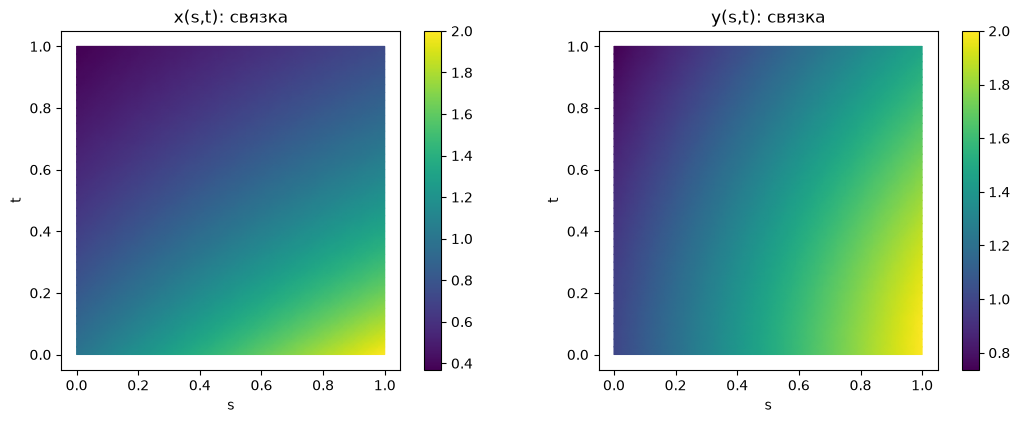

In [10]:
viz = Plotter(sysA, meshA)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
viz.plot_field('X', component=0, ax=axes[0], title='x(s,t): связка')
viz.plot_field('X', component=1, ax=axes[1], title='y(s,t): связка')
plt.tight_layout()
plt.show()


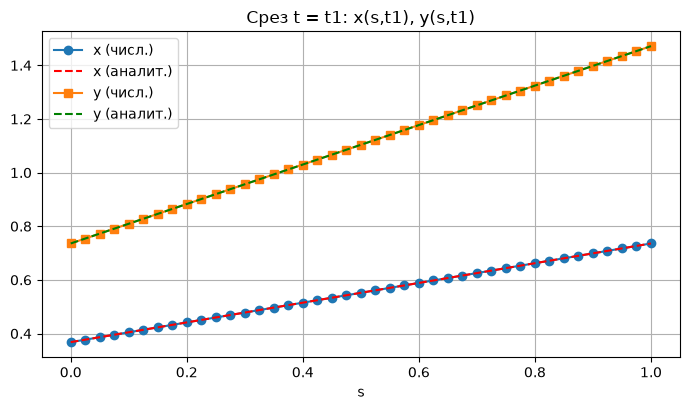

In [11]:
fig, ax = plt.subplots(figsize=(7, 4.2))
viz.plot_slice(
    [('X', 0), (lambda s, t: A['x'](s, t)),
     ('X', 1), (lambda s, t: A['y'](s, t))],
    t=T1, ax=ax,
    labels=['x (числ.)', 'x (аналит.)', 'y (числ.)', 'y (аналит.)'],
    styles=['o-', 'r--', 's-', 'g--'])
ax.set_title('Срез t = t1: x(s,t1), y(s,t1)')
plt.tight_layout()
plt.show()


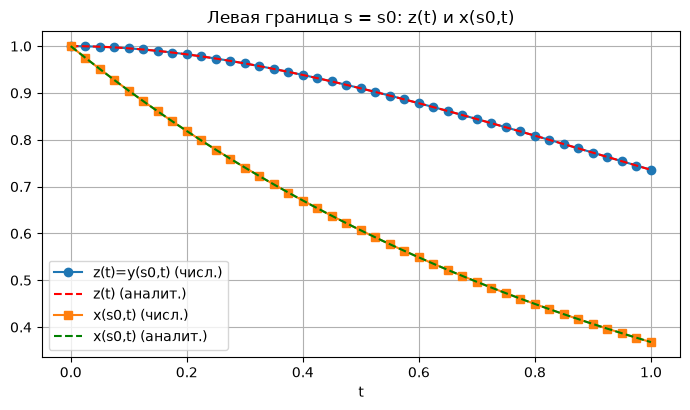

In [12]:
fig, ax = plt.subplots(figsize=(7, 4.2))
viz.plot_slice(
    [('Z_numeric', 0), (lambda s, t: A['z'](t)),
     ('X', 0), (lambda s, t: A['x'](S0, t))],
    s=S0, ax=ax,
    labels=['z(t)=y(s0,t) (числ.)', 'z(t) (аналит.)',
            'x(s0,t) (числ.)', 'x(s0,t) (аналит.)'],
    styles=['o-', 'r--', 's-', 'g--'])
ax.set_title('Левая граница s = s0: z(t) и x(s0,t)')
plt.tight_layout()
plt.show()


## Э5. Сверка с эталоном

* **B (smoke)** — машинная точность ($\Delta\le10^{-13}$).
* **A и C** — таблица $\Delta(m)$ для $m=20,40,80,160$ и наблюдаемый порядок
  $p=\log_2(\Delta(m)/\Delta(2m))\approx2.00$ по $x,y,z$; невязка связки и
  число итераций.
* Согласование с [`case1_reference.py`](../../math/numerics/case1_reference.py).
* **Цикличность** ($\beta\ne0,\ f_w\ne0$) и **падение порядка до ~1** при
  отключении итерации (лаг `x` с предыдущего слоя, `method='explicit'`).

In [13]:
def order_table(name, model, method='auto', ms=(20, 40, 80, 160)):
    print(f'== {name} | method={method} ==')
    print(f"{'m':>5} {'Δx':>11} {'Δy':>11} {'Δz':>11} "
          f"{'px':>5} {'py':>5} {'pz':>5} {'iters':>6} {'res':>9}")
    prev = None
    for m in ms:
        s_, mesh_, cou_, _ = assemble(m, model, method=method)
        s_.solve()
        ex, ey, ez = errors(mesh_, model)
        if prev is None:
            print(f'{m:>5} {ex:>11.3e} {ey:>11.3e} {ez:>11.3e} '
                  f'{"-":>5} {"-":>5} {"-":>5} {cou_.max_iters:>6} '
                  f'{cou_.max_residual:>9.2e}')
        else:
            px = np.log2(prev[0] / ex) if ex > 0 else np.inf
            py = np.log2(prev[1] / ey) if ey > 0 else np.inf
            pz = np.log2(prev[2] / ez) if ez > 0 else np.inf
            print(f'{m:>5} {ex:>11.3e} {ey:>11.3e} {ez:>11.3e} '
                  f'{px:>5.2f} {py:>5.2f} {pz:>5.2f} {cou_.max_iters:>6} '
                  f'{cou_.max_residual:>9.2e}')
        prev = (ex, ey, ez)
    print()


order_table('B smoke (B=F=0)', B)
order_table('A линейная связка', A)
order_table('C нелинейная связка', C)


== B smoke (B=F=0) | method=auto ==
    m          Δx          Δy          Δz    px    py    pz  iters       res
   20   4.441e-16   7.772e-16   6.661e-16     -     -     -      0  7.63e-17
   40   4.441e-16   6.661e-16   6.661e-16  0.00  0.22  0.00      0  1.49e-16
   80   4.441e-16   2.665e-15   2.665e-15  0.00 -2.00 -2.00      0  1.89e-16
  160   4.441e-16   2.665e-15   2.665e-15  0.00  0.00  0.00      0  1.50e-16

== A линейная связка | method=auto ==
    m          Δx          Δy          Δz    px    py    pz  iters       res
   20   1.272e-04   9.369e-05   9.369e-05     -     -     -      0  1.75e-16
   40   3.180e-05   2.341e-05   2.341e-05  2.00  2.00  2.00      0  1.63e-16
   80   7.950e-06   5.852e-06   5.852e-06  2.00  2.00  2.00      0  1.87e-16
  160   1.987e-06   1.463e-06   1.463e-06  2.00  2.00  2.00      0  1.63e-16

== C нелинейная связка | method=auto ==
    m          Δx          Δy          Δz    px    py    pz  iters       res
   20   2.630e-04   3.561e-04   3.561

In [14]:
print('Демонстрация необходимости итерации: лаг x(s0,t) с прошлого слоя')
print('(method="explicit") — порядок падает до ~1:')
order_table('C, explicit lag', C, method='explicit')


Демонстрация необходимости итерации: лаг x(s0,t) с прошлого слоя
(method="explicit") — порядок падает до ~1:
== C, explicit lag | method=explicit ==
    m          Δx          Δy          Δz    px    py    pz  iters       res
   20   7.910e-03   3.471e-02   3.471e-02     -     -     -      2  3.91e-13
   40   3.980e-03   1.730e-02   1.730e-02  0.99  1.00  1.00      2  8.17e-13
   80   1.996e-03   8.635e-03   8.635e-03  1.00  1.00  1.00      2  8.32e-13
  160   9.998e-04   4.314e-03   4.314e-03  1.00  1.00  1.00      2  9.72e-13



### Сверка с `math/numerics/case1_reference.py`

Запускаем эталонный скрипт (те же данные и формулы) и сопоставляем значения.

In [15]:
import importlib
import case1_reference as ref
importlib.reload(ref)

print('--- эталон: smoke (пример B, m=20) ---')
ref.check_smoke()

print('--- эталон: линейная связка A ---')
ref.check_coupled_lin()

print('--- эталон: нелинейная связка C ---')
ref.check_coupled_nl()

# прямое сопоставление max|Δ| для m=40
ref_model_A = dict(B=(0.0, 1.0, 1.0, 0.0), F1=ref.A_F1, F2=ref.A_F2,
                   x0=ref.A_x0, y0=ref.A_y0, N=ref.A_N, f=ref.A_f)
_, mesh_ref, _ = ref.run(40, ref_model_A)
exr, eyr, ezr = ref._errors(mesh_ref, ref.A_x, ref.A_y, ref.A_z)

sysA40, meshA40, couA40, _ = assemble(40, A)
sysA40.solve()
exo, eyo, ezo = errors(meshA40, A)

print()
print(f"{'источник (A, m=40)':>26} {'Δx':>11} {'Δy':>11} {'Δz':>11}")
print(f"{'case1_reference.py':>26} {exr:>11.3e} {eyr:>11.3e} {ezr:>11.3e}")
print(f"{'cascadoc_new + notebook':>26} {exo:>11.3e} {eyo:>11.3e} {ezo:>11.3e}")
print(f"  совпадение Δ: max|разность| = "
      f"{max(abs(exr-exo), abs(eyr-eyo), abs(ezr-ezo)):.2e}")


--- эталон: smoke (пример B, m=20) ---
[check_smoke]  линейный smoke-тест (B=F=0): машинная точность
  m=20: max|Δx|=2.220e-16  max|Δy|=3.331e-16  max|Δz|=3.331e-16  (согласование: max_iter=3, невязка=5.55e-17)

--- эталон: линейная связка A ---
[check_coupled_lin]  линейная связка A: f=w-z, B12=B21=1
    m     max|Δx|     max|Δy|     max|Δz|    px    py    pz  iters       res
   20   1.272e-04   9.369e-05   9.369e-05     -     -     -      3  9.52e-14
   40   3.180e-05   2.341e-05   2.341e-05  2.00  2.00  2.00      2  6.05e-14
   80   7.950e-06   5.852e-06   5.852e-06  2.00  2.00  2.00      2  1.52e-14
  160   1.987e-06   1.463e-06   1.463e-06  2.00  2.00  2.00      2  3.83e-15

  m=20: dT=0.0500, q = (dT/2)(L_z+|beta|L_w) = 0.0253
  m=40: dT=0.0250, q = (dT/2)(L_z+|beta|L_w) = 0.0126

--- эталон: нелинейная связка C ---
[check_coupled_nl]  нелинейная связка В: f=w·z, z=exp(1-e^{-t})
    m     max|Δx|     max|Δy|     max|Δz|    px    py    pz  iters       res
   20   2.630e-04   3.561

### Итог Э5

* **B** — машинная точность ($\sim10^{-16}$), проверяет «проводку» (сборка,
  перенос, ОДУ, связка).
* **A, C** — порядок $p\approx2.00$ по всем $x,y,z$; невязка связки
  $\le10^{-13}$; значения совпадают с `case1_reference.py`.
* **Без итерации** (лаг) порядок $p\approx1.00$ — прямая иллюстрация, что
  итерационное согласование связки на слое необходимо для $O(dt^2)$.